# 07 methods comparison

Compare rank agreement, discrepancies, profile interpretation and methodological trade-offs.

Technical evidence for the confirmed Bremen project. Primary comparison: 2024 Ortsteile. No historical change claim; original data preserved.

## Setup and relative paths

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis_common.py').exists(), 'Run from root or notebooks directory'
sys.path.insert(0, str(ROOT / 'src'))
from analysis_common import load_analysis, FEATURES
def read(relative):
    return pd.read_csv(ROOT / relative, dtype={'geo_code': str})
def show_figure(name):
    display(Image(filename=str(ROOT / 'results' / 'figures' / name)))


## Data loading and preparation

In [2]:
composite = read('results/composite_index_results.csv')
topsis = read('results/topsis_results.csv')
clusters = read('results/kmeans_results.csv')

## Calculation and validation

In [3]:
assert set(composite.geo_code) == set(topsis.geo_code) == set(clusters.geo_code)
display(read('results/ranking_agreement_summary.csv'))
display(read('results/ranking_agreement.csv').head(10))
display(read('results/method_comparison_table.csv'))

,spearman,kendall_tau_b,n
0,0.974294,0.883155,79


,geo_code,geo_name,year,composite_rank,topsis_rank,rank_difference_topsis_minus_composite,absolute_rank_difference
0,252,Rablinghausen,2024,73.0,50.0,-23.0,23.0
1,515,St. Magnus,2024,38.0,57.0,19.0,19.0
2,342,Lehe,2024,49.0,63.0,14.0,14.0
3,525,Fähr-Lobbendorf,2024,10.0,20.0,10.0,10.0
4,361,Oberneuland,2024,60.0,69.0,9.0,9.0
5,385,Mahndorf,2024,54.0,45.0,-9.0,9.0
6,437,Ueberseestadt,2024,16.0,24.0,8.0,8.0
7,311,Steintor,2024,51.0,58.0,7.0,7.0
8,113,Ostertor,2024,42.0,49.0,7.0,7.0
9,334,Neue Vahr Südwest,2024,36.0,29.0,-7.0,7.0


,method,output,normalization,weights,strength,limitation,governance_use
0,Composite index,"score [0,1]; descending rank","min-max, employment reversed",equal 1/3 baseline,transparent arithmetic and per-feature contrib...,compensatory; endpoints and correlated variabl...,auditable screening; inspect components before...
1,TOPSIS,"disadvantage closeness [0,1]; descending rank",column vector norm,equal 1/3 baseline,explicit reference profiles and distance trade...,"scaling, weights and sample-dependent ideals a...",alternative screening; show rank disagreements
2,K-means,2 nominal profile groups,StandardScaler z-scores,no explicit weights; standardized Euclidean ge...,shows similar multidimensional neighborhood pr...,k and scaling choices; no intrinsic ordering; ...,describe differentiated needs; not a deprivati...


## Results, visualization and interpretation

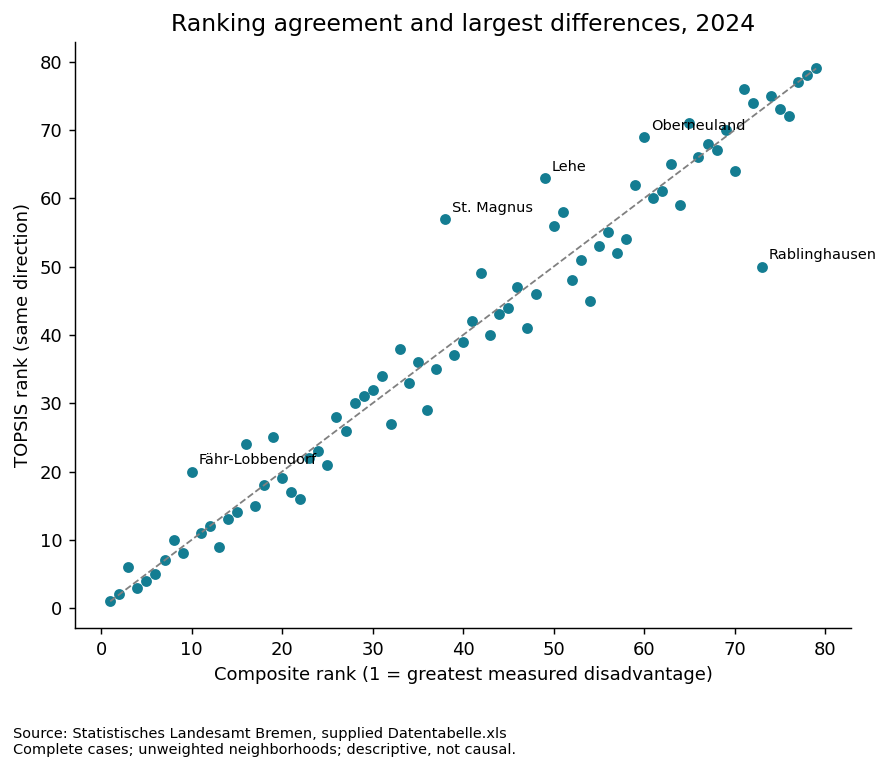

# Method comparison evidence

Shared data: 79 Ortsteile, 2024, three indicators, no imputation. Highest equal-weight composite scores:

| geo_name | composite_score | rank |
| --- | --- | --- |
| Ohlenhof | 0.943 | 1 |
| Gröpelingen | 0.876 | 2 |
| Grohn | 0.821 | 3 |
| Blumenthal | 0.795 | 4 |
| Lindenhof | 0.777 | 5 |
| Tenever | 0.769 | 6 |
| Lüssum-Bockhorn | 0.724 | 7 |
| Kirchhuchting | 0.708 | 8 |
| Bahnhofsvorstadt | 0.698 | 9 |
| Fähr-Lobbendorf | 0.693 | 10 |

Highest TOPSIS disadvantage closeness:

| geo_name | topsis_score | rank |
| --- | --- | --- |
| Ohlenhof | 0.971 | 1 |
| Gröpelingen | 0.911 | 2 |
| Blumenthal | 0.810 | 3 |
| Lindenhof | 0.796 | 4 |
| Tenever | 0.767 | 5 |
| Grohn | 0.738 | 6 |
| Lüssum-Bockhorn | 0.726 | 7 |
| Bahnhofsvorstadt | 0.726 | 8 |
| Neuenland | 0.699 | 9 |
| Kirchhuchting | 0.696 | 10 |

Rank Spearman 0.9743; Kendall tau-b 0.8832. Agreement is within-sample consistency, not evidence of correct identification of true poverty. Both scores are relative, with different normalizations and aggregation geometries.

Largest rank differences and observed percentages (unemployment, employment, benefits; all 2024):

| geo_name | composite_rank | topsis_rank | unemployment | employment | benefit_receipt |
| --- | --- | --- | --- | --- | --- |
| Rablinghausen | 73.000 | 50.000 | 9.073 | 72.401 | 10.984 |
| St. Magnus | 38.000 | 57.000 | 9.229 | 51.704 | 6.176 |
| Lehe | 49.000 | 63.000 | 6.676 | 54.140 | 6.251 |
| Fähr-Lobbendorf | 10.000 | 20.000 | 17.411 | 44.159 | 17.669 |
| Oberneuland | 60.000 | 69.000 | 5.466 | 56.202 | 4.471 |
| Mahndorf | 54.000 | 45.000 | 9.290 | 64.645 | 12.379 |
| Ueberseestadt | 16.000 | 24.000 | 14.129 | 47.633 | 19.422 |
| Steintor | 51.000 | 58.000 | 8.126 | 58.080 | 7.624 |

Min-max equal-weight scoring gives each observed indicator range equal contribution. TOPSIS vector normalization gives columns different effective spreads, and closeness uses Euclidean distances. The differing observed profiles explain why an employment weakness can change rank differently from a benefit-receipt weakness; no causal explanation of neighborhood conditions is inferred.

K-means selected k=2; mean silhouette 0.5277. Labels are nominal:

- Profile A: n=51; unemployment 8.45%, employment 61.40%, SGB II receipt 9.82%.
- Profile B: n=28; unemployment 18.08%, employment 53.58%, SGB II receipt 23.99%.

The same profile has the highest unemployment and benefit receipt and the lowest employment, supporting a relative disadvantage description on these three indicators. No Profile A/B ordering is inferred. Stability evidence is in robustness_findings.md; cluster count is an algorithmic diagnostic choice, not a proven municipal taxonomy.

Interpretability: the composite average is easiest to reconstruct; TOPSIS requires understanding normalization and hypothetical ideals; clusters require inspecting profiles rather than reading rank numbers. Transparency depends on publishing definitions, weights, coverage and traces for all three. Robustness tests show dependence on analyst choices. Data requirements are a complete consistent numeric matrix; K-means additionally requires enough varied observations and standardized scales. No winner is declared.

Figures and evidence: composite_ranking.png, ranking_agreement.png, cluster_profiles.png, cluster_projection.png, kmeans_diagnostics.png, weight_sensitivity.png. Rankings may guide questions for planners, not dictate budgets or individual eligibility. Wider income, education, housing and health indicators, denominator counts, source-definition verification and external validation are needed for a general disadvantage measure.


In [4]:
show_figure('ranking_agreement.png')
display(Markdown((ROOT / 'results/method_comparison.md').read_text(encoding='utf-8')))

## Assumptions and limits

Complete-case scoring; no imputation. Different indicator denominators, correlated labour-market measures, unavailable 2024 income, unknown exact reference dates and incomplete historical boundary/definition metadata limit interpretation. Rankings apply only to the covered sample. Clusters are nominal. See analysis/dataset_validation.md and docs/methods.md. Tables are exported by reusable scripts; important figures appear in results/figures/.